# Step 3: Separate each day's pattern from its size

**Project:** Learning What "Normal" Looks Like: Clustering-Based Contextual Anomaly Detection in Bike Sharing

Step 1 found that daily rentals grew by 64% from 2011 to 2012. If days are clustered on raw counts, the clusters will partly separate the two years instead of separating ways of riding. This notebook:

1. confirms the growth with seasonal-trend decomposition (Time Series Analysis, Slide 27);
2. splits every day into two parts, for all riders, casual riders and registered riders:
    - **shape**: the share of the day's rentals in each hour (24 values that sum to 1);
    - **level**: the day's total compared with the typical total of the surrounding 30 days;
3. checks with PCA (Anomaly Detection 2, Slides 17 to 22) and the silhouette score (Clustering, Slides 88 to 89) that the shape describes *how* people ride rather than *which year* it is.

**Inputs:** `day_matrix.csv`, `day_matrix_casual.csv`, `day_matrix_registered.csv`, `day_info.csv` (from Step 2).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from statsmodels.tsa.seasonal import STL

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})

GROUPS = {"all": "day_matrix.csv", "casual": "day_matrix_casual.csv", "registered": "day_matrix_registered.csv"}
X = {g: pd.read_csv(f, index_col="dteday", parse_dates=True) for g, f in GROUPS.items()}
info = pd.read_csv("day_info.csv", index_col="dteday", parse_dates=True)
totals = pd.DataFrame({g: m.sum(axis=1) for g, m in X.items()})
print({g: m.shape for g, m in X.items()})

{'all': (731, 24), 'casual': (731, 24), 'registered': (731, 24)}


## 1. Confirm the growth: seasonal-trend decomposition

STL splits the daily total into three parts (Time Series Analysis, Slides 16 to 21 and 27):

- **trend**: the slow change in demand level;
- **weekly seasonality**: the repeating pattern over the 7 days of the week (`period = 7`);
- **residual**: what is left, including unusual days.

`robust=True` stops a few extreme days (such as storms) from bending the trend.

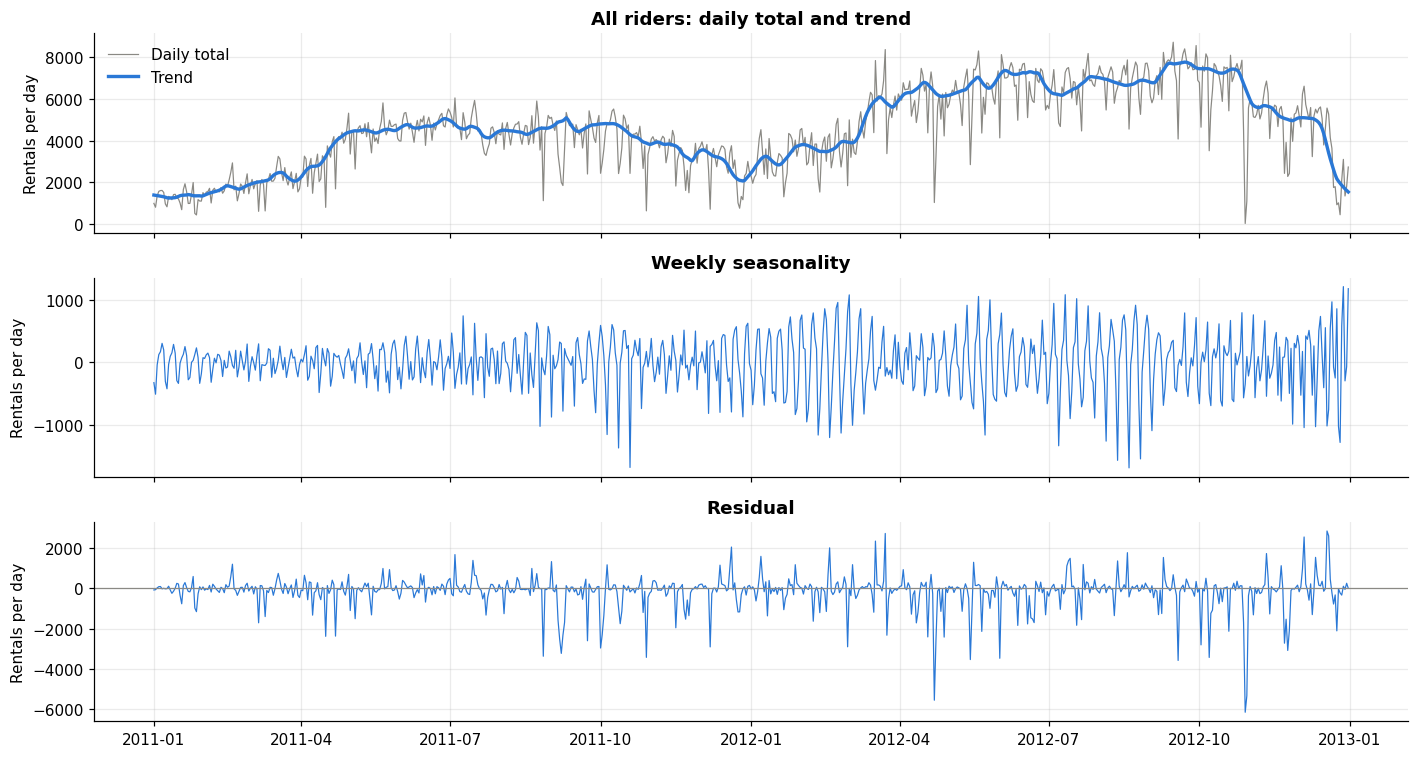

In [2]:
stl = {g: STL(totals[g], period=7, robust=True).fit() for g in GROUPS}

fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
r = stl["all"]
axes[0].plot(totals.index, totals["all"], color=GREY, linewidth=0.8, label="Daily total")
axes[0].plot(totals.index, r.trend, color=BLUE, linewidth=2.2, label="Trend")
axes[0].set(title="All riders: daily total and trend", ylabel="Rentals per day")
axes[0].legend(frameon=False, loc="upper left")
axes[1].plot(totals.index, r.seasonal, color=BLUE, linewidth=0.8)
axes[1].set(title="Weekly seasonality", ylabel="Rentals per day")
axes[2].plot(totals.index, r.resid, color=BLUE, linewidth=0.8)
axes[2].axhline(0, color=GREY, linewidth=0.8)
axes[2].set(title="Residual", ylabel="Rentals per day")
fig.tight_layout()
plt.show()

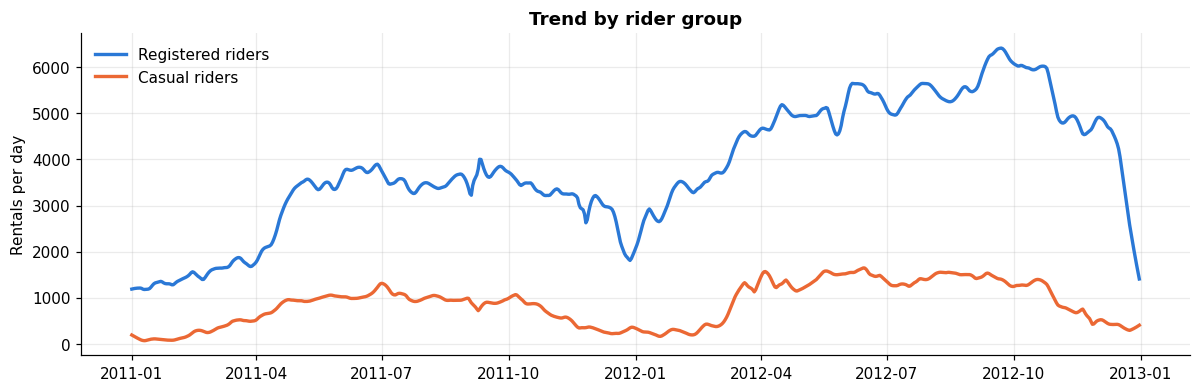

Mean trend per year (rentals per day):
           all  casual  registered
dteday                            
2011    3531.0   680.0      2845.0
2012    5781.0  1038.0      4757.0

Growth 2011 to 2012: {'all': '64%', 'casual': '53%', 'registered': '67%'}


In [3]:
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(totals.index, stl["registered"].trend, color=BLUE, linewidth=2.2, label="Registered riders")
ax.plot(totals.index, stl["casual"].trend, color=ORANGE, linewidth=2.2, label="Casual riders")
ax.set(title="Trend by rider group", ylabel="Rentals per day")
ax.legend(frameon=False, loc="upper left")
plt.show()

trend_by_year = pd.DataFrame({g: stl[g].trend.groupby(totals.index.year).mean() for g in GROUPS}).round(0)
growth = (trend_by_year.loc[2012] / trend_by_year.loc[2011] - 1).map("{:.0%}".format)
print("Mean trend per year (rentals per day):")
print(trend_by_year.to_string())
print("\nGrowth 2011 to 2012:", growth.to_dict())

**Result.** The trend rises strongly over the two years for both rider groups, on top of the summer and winter cycle. The growth is a property of the whole system (more stations, more members), not of individual days, so it has to be removed before days are compared with each other.

## 2. Shape: how the day's rentals are spread over 24 hours

The shape of a day is each hour's count divided by the day's total. A commuting day then looks the same in 2011 and 2012, even though 2012 is busier.

**Problem with small totals.** Casual riders have fewer than 100 rentals on about 44 days (mostly in winter, as low as 2). With so few rentals, the shape is mostly chance: 2 rentals in one hour would make that hour 100% of the day.

**Fix: smoothing toward the average shape.** Before dividing, a small number of extra rentals (`ALPHA = 50`) is added, spread like the group's average day. On a normal day with 1,000 rentals this changes the shape by about 5%. On a day with 10 rentals, the shape stays close to the average, which honestly reflects how little that day tells us. This is the same idea as adding pseudo-counts before estimating proportions.

The choice of `ALPHA` is a parameter to report and, if time allows, to vary in a sensitivity check.

In [4]:
ALPHA = 50

def day_shape(m, alpha=ALPHA):
    average_shape = m.sum() / m.values.sum()          # the group's typical day, sums to 1
    smoothed = m.add(alpha * average_shape, axis=1)
    return smoothed.div(m.sum(axis=1) + alpha, axis=0)

shape = {g: day_shape(m) for g, m in X.items()}

for g, s in shape.items():
    assert np.allclose(s.sum(axis=1), 1), g
    small = (totals[g] < 100).sum()
    print(f"{g:10s}: rows sum to 1 | days with fewer than 100 rentals: {small}")

all       : rows sum to 1 | days with fewer than 100 rentals: 1
casual    : rows sum to 1 | days with fewer than 100 rentals: 44
registered: rows sum to 1 | days with fewer than 100 rentals: 1


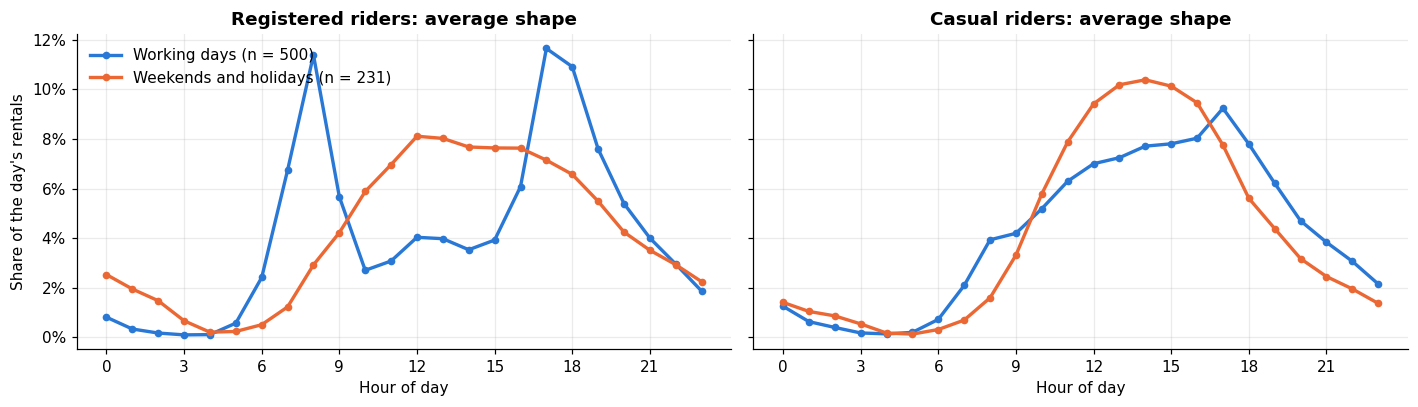

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
work = info.workingday == 1
hours = np.arange(24)
for ax, g in zip(axes, ["registered", "casual"]):
    ax.plot(hours, shape[g][work].mean(), color=BLUE, linewidth=2.2, marker="o", markersize=4,
            label=f"Working days (n = {work.sum()})")
    ax.plot(hours, shape[g][~work].mean(), color=ORANGE, linewidth=2.2, marker="o", markersize=4,
            label=f"Weekends and holidays (n = {(~work).sum()})")
    ax.set(title=f"{g.capitalize()} riders: average shape", xlabel="Hour of day", xticks=range(0, 24, 3))
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
axes[0].set_ylabel("Share of the day's rentals")
axes[0].legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

**Two very different riding styles.** Registered riders have sharp commuting peaks on working days and a midday curve on days off. Casual riders have a broad midday to afternoon curve on *both* kinds of day, with only a small extra bump around 17:00 on working days: their shape depends much less on whether it is a working day. This is the first concrete evidence that the two groups should be analysed separately (second research question).

## 3. Level: how big the day is compared with its neighbours

The level of a day compares its total with the **typical total of similar nearby days**:

level = log2( total / median total of days of the same kind within 15 days before or after )

"Same kind" means working days are compared with working days, and weekends and holidays with weekends and holidays. A first version compared every day with the plain 30-day median, but the weekly cycle then dominated: casual riders roughly double at weekends, so every weekend looked "unusually high". Comparing like with like removes that, and holidays are compared with weekends, which matches how people ride on them.

- level = 0: a normal day of its kind for that time of year
- level = -1: half the usual rentals
- level = +1: double the usual rentals

Comparing with *nearby* days removes both the growth and the summer and winter cycle, so a quiet January day is not confused with a storm in July. The base-2 logarithm makes halving and doubling symmetric.

In [6]:
def day_level(total, kind, half_window=15):
    typical = pd.Series(index=total.index, dtype=float)
    for d in total.index:
        nearby = (np.abs((total.index - d).days) <= half_window) & (kind == kind[d])
        typical[d] = total[nearby].median()
    return np.log2(total.clip(lower=1) / typical)

level = pd.DataFrame({f"level_{g}": day_level(totals[g], info.workingday) for g in GROUPS})
level = level.join(totals.add_prefix("total_"))

# A typical day of either kind should sit at 0.
print(level.filter(like="level_").groupby(info.workingday).median().round(2).rename(index={0: "day off", 1: "working day"}))
level.describe().round(2)

             level_all  level_casual  level_registered
workingday                                            
day off            0.0           0.0               0.0
working day        0.0           0.0               0.0


,level_all,level_casual,level_registered,total_all,total_casual,total_registered
count,731.00,731.00,731.00,731.00,731.00,731.00
mean,-0.10,-0.09,-0.10,4504.35,848.18,3656.17
std,0.51,0.78,0.49,1937.21,686.62,1560.26
min,-8.06,-8.47,-8.03,22.00,2.00,20.00
25%,-0.15,-0.32,-0.15,3152.00,315.50,2497.00
50%,0.00,0.00,0.00,4548.00,713.00,3662.00
75%,0.10,0.28,0.09,5956.00,1096.00,4776.50
max,0.98,2.53,0.95,8714.00,3410.00,6946.00


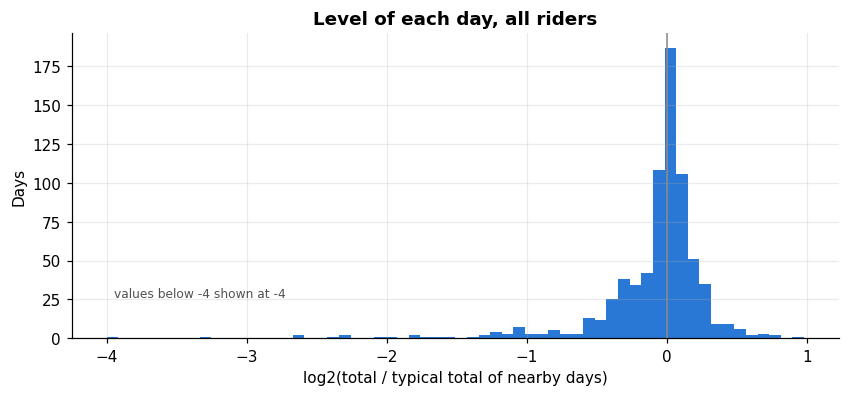

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(level["level_all"].clip(lower=-4), bins=60, color=BLUE)
ax.axvline(0, color=GREY, linewidth=1)
ax.set(title="Level of each day, all riders", xlabel="log2(total / typical total of nearby days)",
       ylabel="Days")
ax.annotate("values below -4 shown at -4", (-4, 2), xytext=(5, 25), textcoords="offset points",
            fontsize=8, color="#52514e")
plt.show()

**Result.** Most days lie close to 0, as expected. A long tail to the left holds days with far fewer rentals than their neighbours; these are candidate anomalies. The most extreme day is about 8 halvings below normal, which is one reason the axis is clipped.

The level is **not** inspected day by day here. Which days are unusual is decided by the detectors in Step 6 and compared with the events list only at evaluation, so the evaluation stays fair.

## 4. Check: does the shape describe riding style instead of the year?

Each representation (raw counts, shape) is projected onto its first two principal components (PCA). The silhouette score then measures how well a known label separates the days in that space (Clustering, Slides 88 to 89): close to 0 means the label does not separate the days, and higher means it does.

The goal of Step 3 is a representation where the **year** does not separate the days, but the **riding style** (working day or not) still does. Raw counts are standardised per hour first, so busy hours do not dominate PCA.

In [8]:
def separation(m, label):
    z = PCA(n_components=2).fit_transform(m)
    return silhouette_score(z, label)

rows = []
for g in GROUPS:
    raw = X[g].values
    raw_std = (raw - raw.mean(0)) / raw.std(0)
    for name, m in [("raw counts", raw_std), ("shape", shape[g].values - shape[g].values.mean(0))]:
        rows.append({"riders": g, "representation": name,
                     "separates by year": separation(m, info.yr),
                     "separates by working day": separation(m, info.workingday)})
check = pd.DataFrame(rows).set_index(["riders", "representation"]).round(3)
check

separates by year  separates by working day
riders     representation                                             
all        raw counts                  0.169                     0.397
           shape                      -0.001                     0.698
casual     raw counts                  0.031                     0.322
           shape                       0.009                     0.274
registered raw counts                  0.207                     0.400
           shape                       0.000                     0.718

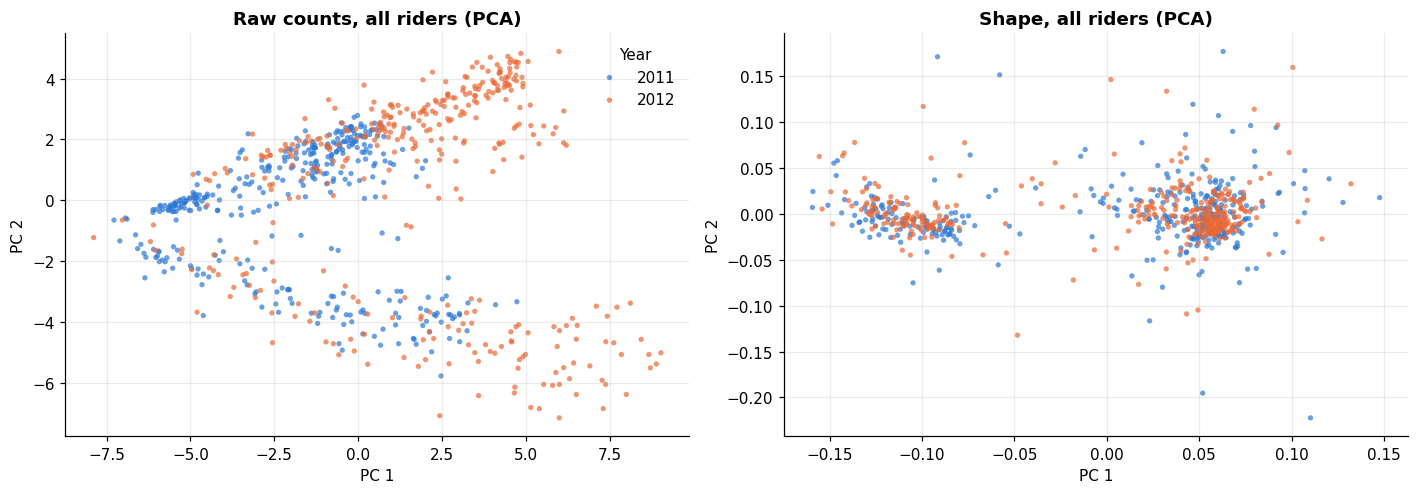

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
raw = X["all"].values
for ax, (name, m) in zip(axes, [("Raw counts", (raw - raw.mean(0)) / raw.std(0)),
                                ("Shape", shape["all"].values - shape["all"].values.mean(0))]):
    z = PCA(n_components=2).fit_transform(m)
    for yr, color, label in [(0, BLUE, "2011"), (1, ORANGE, "2012")]:
        sel = (info.yr == yr).values
        ax.scatter(z[sel, 0], z[sel, 1], s=12, color=color, alpha=0.7, label=label, edgecolors="none")
    ax.set(title=f"{name}, all riders (PCA)", xlabel="PC 1", ylabel="PC 2")
axes[0].legend(frameon=False, title="Year")
fig.tight_layout()
plt.show()

**Result.** For all riders and for registered riders, the year separation drops to about 0 with the shape, while the working-day separation becomes much stronger. The split does what it was designed to do: the shape captures riding style, and growth is moved into the level.

Casual riders behave differently: their shape separates working days only weakly, consistent with the plot in Section 2. Whatever drives casual riding patterns (weather, tourism, events) is not the working-day label. This supports clustering casual days separately.

## 5. Save

In [10]:
for g, s in shape.items():
    s.to_csv(f"shape_{g}.csv")
level.to_csv("level.csv")

for g in GROUPS:
    back = pd.read_csv(f"shape_{g}.csv", index_col="dteday", parse_dates=True)
    assert back.shape == (731, 24) and np.allclose(back.sum(axis=1), 1)
print("Saved shape_all.csv, shape_casual.csv, shape_registered.csv, level.csv")

Saved shape_all.csv, shape_casual.csv, shape_registered.csv, level.csv


## Summary for the report

- STL confirms a strong upward trend from 2011 to 2012 for both rider groups.
- Each day is split into a **shape** (24 hourly shares, smoothed with 50 pseudo-rentals so low-count days are not dominated by chance) and a **level** (log2 of the total relative to the 30-day rolling median).
- With raw counts, days partly separate by year; with the shape, the year no longer separates them while working days separate much more clearly (silhouette scores in Section 4).
- Registered riders' shapes depend strongly on working day versus day off; casual riders' shapes hardly do, which motivates analysing the two groups separately.

**Next, Step 5:** cluster the shapes into day types (k-means, hierarchical, GMM, DBSCAN) and choose the number of clusters.